In [3]:
# Importing the libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
import scipy as scipy

In [5]:
dataset = pd.read_csv("./datasets/insurance_data.csv")
dataset.head()

,age,bmi,charges,gender,region
0,19,28,16885,female,southwest
1,62,26,27809,female,east
2,48,28,23568,male,southwest
3,53,23,23245,female,east
4,20,22,14712,female,northwest


Our goal here is identify whether the average changes are the same for all the regions

H0: mu south = mu east = mu north

H1: there is at least one mu that is different

<Figure size 640x480 with 0 Axes>

d:\anaconda\Lib\site-packages\IPython\core\events.py:93: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  func(*args, **kwargs)
d:\anaconda\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


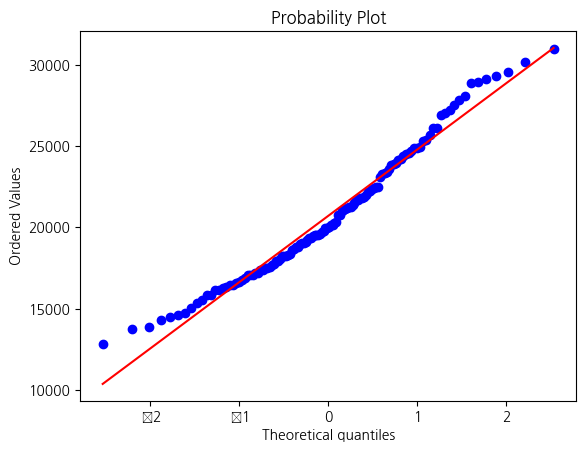

<Figure size 640x480 with 0 Axes>

In [6]:
#We need to check the normality of the data

#QQ-plot
stats.probplot(dataset.charges, plot=plt)
plt.figure()

Normality test: Shapiro Wilk test/ This test is a hypothesis that will help us to decide whether the data is normal or not

H0: the data is normally distributed

H1: the data is nor normally distributed

In [7]:
# Option 1: we check the normality of the data for the entire variable

stats.shapiro(dataset.charges)

ShapiroResult(statistic=0.9718136191368103, pvalue=0.01067691296339035)

In [ ]:
# 0.01 < a (0.05)
# REJECT

When this happens, we can analyse the data in segmentation, and check normality individually.

It could happen that the data is good to go, or maybe we have to remove one of the categories to keep with our analysis.

In [10]:
# Option 2: we analyse the normality by categories

# We check the normality for east
stats.shapiro(dataset.charges[dataset.region == 'east'])

# 0.1 > a (0.05)
# ACCEPT

ShapiroResult(statistic=0.9700243473052979, pvalue=0.10049082338809967)

In [11]:
# south

In [12]:
# north

Two out of the 3 conditions are met. Now we need to check the equality of the variances. For that, we will use the Levene test

In [13]:
# We create variables per region

east = dataset.charges[dataset.region == 'east']
south = dataset.charges[dataset.region == 'southwest']
north = dataset.charges[dataset.region == 'northwest']

In [14]:
# Levene test
# H0: the variances are eqal in all the locations 
# H1: the variances are nto equal

In [15]:
from scipy.stats import levene

In [16]:
levene(east, south, north, center = 'mean') # we assume data is normal

LeveneResult(statistic=0.9081132811476632, pvalue=0.40601496082599176)

# 3 conditions met -> We are ready for ANOVA

We already stated the hypothesis earlier. We will repeat it here.

H0: average charges are the same for all the locations

H1: there is at least one average different thatn the others

In [18]:
# model = ols('X ~ categorical variable', data = df)

model = ols('charges~region', data = dataset).fit()
aov = sm.stats.anova_lm(model, type = 2) # analyzing 2 different variables
aov

,df,sum_sq,mean_sq,F,PR(>F)
region,2.0,4.396982e+07,2.198491e+07,1.334448,0.26715
Residual,121.0,1.993463e+09,1.647490e+07,NaN,NaN


In [ ]:
# p_value = 0.26 > a (0.05)
# We accept the H0

# At a 5% significance level there is enough evidence to confirm that the avg charges per regions are the same